# Bài 13: Phát hiện Vật thể (Object Detection) — Từ R-CNN, SSD, YOLO, DETR đến Huấn luyện Thực tế

## 1. Mục tiêu học tập
- Hiểu bài toán **Object Detection**: Đầu vào là 1 bức ảnh có thể chứa `0, 1` hoặc `nhiều` vật thể → Đầu ra là danh sách các bộ ba `(Bounding Box, Class Label, Confidence Score)`.
- Nắm vững bản đồ 3 họ mô hình Object Detection:
  1. **Two-stage (Hai giai đoạn)**: `R-CNN`, `Fast R-CNN`, **`Faster R-CNN + FPN`** (Đề xuất vùng ứng viên bằng `RPN` rồi phân loại/tinh chỉnh trên từng vùng `RoIAlign`).
  2. **One-stage (Một giai đoạn)**: **`SSD`**, **`RetinaNet`** (với `Focal Loss`), và **họ `YOLO`** (dự đoán trực tiếp trên lưới ô, tốc độ thời gian thực).
  3. **Transformer-based**: **`DETR`**, `Deformable DETR`, `RT-DETR` (dùng `Object Queries` và ghép cặp `Hungarian Matching`, không cần `NMS`).
- Thành thạo các khái niệm và thuật toán cốt lõi:
  - Chuyển đổi 3 định dạng tọa độ hộp: `Pascal VOC (xyxy)`, `COCO (xywh)`, `YOLO (cxcywh normalized)`.
  - Tính chỉ số chồng lấp **`IoU (Intersection over Union)`**.
  - Cài đặt tường minh thuật toán **`NMS (Non-Maximum Suppression)`** và tính độ đo **`AP / mAP@0.5`**.
- **Thực hành chuẩn mực**:
  - Hướng dẫn chuẩn bị dữ liệu chú thích (`Annotation format`).
  - Phân biệt rõ bước chạy **Pretrained Inference** với **Pipeline Fine-Tuning thực tế** bằng API chính thức `torchvision.models.detection.fasterrcnn_mobilenet_v3_large_320_fpn`.

## 2. Kiến thức cần có
- Đã hoàn thành Bài 10, 11, 12.

## 3. Thời gian học dự kiến
- Khoảng **3.0 giờ** (ước tính).

## 4. Bài toán thực tế đơn giản
Trên băng chuyền xuất hiện đồng thời nhiều chi tiết (`circle`, `square`, `triangle`) ở các vị trí và kích thước khác nhau. Mô hình phân loại ảnh thông thường chỉ trả lời được 1 nhãn cho cả bức ảnh; ta cần một bộ **Detector** vừa khoanh khung chữ nhật quanh từng chi tiết vừa gắn nhãn lớp chính xác.

## 5. Giải thích trực quan: Quy trình Hoạt động và Ý nghĩa Keyword
| Keyword | Nghĩa tiếng Việt | Nhóm | Định nghĩa, Vai trò & Ảnh hưởng khi Tăng/Giảm |
|---|---|---|---|
| `bounding box` | Khung giới hạn chữ nhật | Detection | Biểu diễn bằng `[x_min, y_min, x_max, y_max]` (yêu cầu `x_max > x_min` và `y_max > y_min`). |
| `anchor` | Khung neo / Khung mẫu | Detection | Các hộp mẫu đặt tại mỗi điểm lưới trên feature map. Mạng học độ lệch $(\Delta x, \Delta y, \Delta w, \Delta h)$ so với anchor. |
| `objectness` | Điểm xác suất có vật thể | Detection | Điểm số báo vùng khung đó chứa vật thể thật hay chỉ là phông nền (`background`). |
| `IoU` | Tỷ lệ Giao trên Hợp | Đánh giá | $\text{IoU} = \frac{\text{Area}(B_1 \cap B_2)}{\text{Area}(B_1 \cup B_2)} \in [0, 1]$. Dùng để ghép anchor với nhãn thật, chạy NMS và tính mAP. |
| `NMS (iou_threshold)` | Triệt tiêu phi cực đại | Triển khai | Loại bỏ các hộp dự đoán trùng lặp quanh cùng 1 vật thể. **Tăng `iou_threshold`** (ví dụ `0.8`): giữ lại nhiều hộp chồng nhau (tăng FP); **Giảm quá thấp** (`0.2`): xóa nhầm vật thể đứng cạnh nhau (giảm Recall). |
| `AP` & `mAP@0.5` | Độ chính xác trung bình | Đánh giá | `AP` là diện tích dưới đường cong Precision–Recall của 1 lớp; `mAP@0.5` là trung bình `AP` qua mọi lớp tại ngưỡng khớp hộp `IoU >= 0.5`. |

## 6 & 7. Công thức Chuyển đổi Tọa độ Hộp & Ví dụ Số Nhỏ
Trên bức ảnh rộng $W = 100$, cao $H = 100$, xét 1 vật thể có khung:
- **Pascal VOC (`xyxy`)**: $[x_{\min}, y_{\min}, x_{\max}, y_{\max}] = [20, 30, 60, 80]$.
- **COCO (`xywh`)**: $[x_{\min}, y_{\min}, w, h] = [20, 30, 60-20, 80-30] = [20, 30, 40, 50]$.
- **YOLO (`cxcywh` chuẩn hóa `[0, 1]`)**:
  $$c_x = \frac{20 + 60}{2 \times 100} = 0.40, \quad c_y = \frac{30 + 80}{2 \times 100} = 0.55, \quad w_n = \frac{40}{100} = 0.40, \quad h_n = \frac{50}{100} = 0.50$$


In [1]:
# Cell 1: Chuyển đổi 3 Định dạng Tọa độ Hộp (VOC xyxy <-> COCO xywh <-> YOLO cxcywh) & Tính IoU
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

from src.utils import set_seed, get_device
from src.synthetic_data import generate_detection_dataset
from src.evaluation import compute_bbox_iou

QUICK_RUN = True
set_seed(42)
device = get_device()


def xyxy_to_xywh(box_xyxy: np.ndarray) -> np.ndarray:
    x1, y1, x2, y2 = box_xyxy
    return np.array([x1, y1, x2 - x1, y2 - y1], dtype=np.float32)


def xyxy_to_yolo(box_xyxy: np.ndarray, img_w: int, img_h: int) -> np.ndarray:
    x1, y1, x2, y2 = box_xyxy
    return np.array([(x1 + x2) / (2.0 * img_w), (y1 + y2) / (2.0 * img_h), (x2 - x1) / img_w, (y2 - y1) / img_h], dtype=np.float32)


box_voc = np.array([20.0, 30.0, 60.0, 80.0], dtype=np.float32)
print("Pascal VOC [x_min, y_min, x_max, y_max] :", box_voc)
print("COCO       [x_min, y_min, width, height]:", xyxy_to_xywh(box_voc))
print("YOLO norm  [cx, cy, w, h] (trên 100x100):", xyxy_to_yolo(box_voc, 100, 100))

box_pred = np.array([25.0, 35.0, 65.0, 80.0], dtype=np.float32)
print(f"IoU giữa box thật {box_voc.tolist()} và box dự đoán {box_pred.tolist()}: {compute_bbox_iou(box_voc, box_pred):.4f}")


Pascal VOC [x_min, y_min, x_max, y_max] : [20. 30. 60. 80.]
COCO       [x_min, y_min, width, height]: [20. 30. 40. 50.]
YOLO norm  [cx, cy, w, h] (trên 100x100): [0.4  0.55 0.4  0.5 ]
IoU giữa box thật [20.0, 30.0, 60.0, 80.0] và box dự đoán [25.0, 35.0, 65.0, 80.0]: 0.7079


In [2]:
# Cell 2: Cài đặt Tường minh Thuật toán NMS (Non-Maximum Suppression) và Minh họa Trực quan
def nms_numpy(boxes: np.ndarray, scores: np.ndarray, iou_threshold: float = 0.45) -> list[int]:
    """
    Thuật toán Non-Maximum Suppression (NMS) bằng NumPy thuần:
    Loại bỏ các khung dự đoán dư thừa chồng lấp cao quanh cùng một vật thể.
    """
    order = np.argsort(scores)[::-1].tolist()
    keep: list[int] = []
    while order:
        best_idx = order.pop(0)
        keep.append(best_idx)
        remaining = []
        for idx in order:
            if compute_bbox_iou(boxes[best_idx], boxes[idx]) <= iou_threshold:
                remaining.append(idx)
        order = remaining
    return keep


# Giả lập 4 khung dự đoán chồng lấp quanh 1 vật thể và 1 khung quanh vật thể thứ hai
cand_boxes = np.array([
    [18.0, 20.0, 54.0, 56.0],  # Điểm cao nhất 0.95 (Vật thể 1)
    [20.0, 22.0, 56.0, 58.0],  # Trùng lặp với hộp 0 (score 0.82)
    [16.0, 19.0, 52.0, 55.0],  # Trùng lặp với hộp 0 (score 0.75)
    [60.0, 40.0, 88.0, 72.0],  # Vật thể 2 độc lập (score 0.91)
], dtype=np.float32)
cand_scores = np.array([0.95, 0.82, 0.75, 0.91], dtype=np.float32)

kept_manual = nms_numpy(cand_boxes, cand_scores, iou_threshold=0.45)
kept_torch = torchvision.ops.nms(torch.from_numpy(cand_boxes), torch.from_numpy(cand_scores), iou_threshold=0.45).tolist()
print("Chỉ số hộp giữ lại sau NMS (cài đặt tay):", kept_manual)
print("Chỉ số hộp giữ lại sau NMS (torchvision):", kept_torch)
assert kept_manual == kept_torch, "NMS cài đặt tay phải khớp 100% với torchvision.ops.nms!"


Chỉ số hộp giữ lại sau NMS (cài đặt tay): [0, 3]
Chỉ số hộp giữ lại sau NMS (torchvision): [0, 3]


In [3]:
# Cell 3: Chuẩn bị Annotation & Dataset Chuẩn cho Torchvision Object Detection
# Lưu ý quan trọng trong Torchvision Detection API:
# - Nhãn 0 LUÔN dành riêng cho nền (background).
# - Các lớp vật thể được đánh số từ 1..K (1: circle, 2: square, 3: triangle).
# - Mỗi mẫu trả về: (image_tensor [C, H, W] float32 trong [0, 1], target_dict {'boxes': FloatTensor[M, 4], 'labels': Int64Tensor[M]})
det_class_map = {0: "background", 1: "circle", 2: "square", 3: "triangle"}
raw_det_data = generate_detection_dataset(num_images=24 if QUICK_RUN else 60, image_size=96, max_objects=2, seed=42)

# Kiểm tra định dạng Annotation của mẫu đầu tiên
sample0 = raw_det_data[0]
print("Cấu trúc Annotation chuẩn của mẫu #0:")
print("  - Image shape :", sample0["image"].shape)
print("  - Boxes (xyxy):", sample0["boxes"].round(1).tolist())
print("  - Labels (1..3):", sample0["labels"].tolist(), "->", [det_class_map[int(c)] for c in sample0["labels"]])


def to_torchvision_Format(records: list[dict]) -> list[tuple[torch.Tensor, dict[str, torch.Tensor]]]:
    formatted = []
    for item in records:
        img_t = torch.from_numpy(item["image"]).permute(2, 0, 1).float() / 255.0
        target_t = {
            "boxes": torch.from_numpy(item["boxes"]).float(),
            "labels": torch.from_numpy(item["labels"]).long(),
        }
        formatted.append((img_t, target_t))
    return formatted


det_pairs = to_torchvision_Format(raw_det_data)
train_det = det_pairs[:16]
val_det = det_pairs[16:]


Cấu trúc Annotation chuẩn của mẫu #0:
  - Image shape : (96, 96, 3)
  - Boxes (xyxy): [[30.0, 26.0, 60.0, 55.0]]
  - Labels (1..3): [3] -> ['triangle']


Faster R-CNN Epoch 1/3 -> Total Detection Loss = 2.0871 (Gồm: ['loss_classifier', 'loss_box_reg', 'loss_objectness', 'loss_rpn_box_reg'])
Faster R-CNN Epoch 2/3 -> Total Detection Loss = 0.9113 (Gồm: ['loss_classifier', 'loss_box_reg', 'loss_objectness', 'loss_rpn_box_reg'])
Faster R-CNN Epoch 3/3 -> Total Detection Loss = 0.4015 (Gồm: ['loss_classifier', 'loss_box_reg', 'loss_objectness', 'loss_rpn_box_reg'])


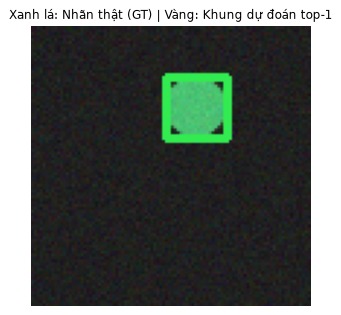

In [4]:
# Cell 4: Thực hành Huấn luyện / Fine-Tuning Thực tế Faster R-CNN (MobileNetV3-FPN) trên Tập Nhỏ
# Lưu ý:
# - Ở chế độ Offline (mặc định trong bài để không tự tải file lớn): khởi tạo fasterrcnn_mobilenet_v3_large_320_fpn(weights=None, weights_backbone=None)
# - Khi có Internet: đặt weights="DEFAULT" để nạp trọng số COCO pretrained, sau đó thay box_predictor cho số lớp mới.
set_seed(42)
detector = fasterrcnn_mobilenet_v3_large_320_fpn(weights=None, weights_backbone=None, num_classes=4)
in_features_roi = detector.roi_heads.box_predictor.cls_score.in_features
detector.roi_heads.box_predictor = FastRCNNPredictor(in_features_roi, num_classes=4)  # 0: bg + 3 lớp hình
detector.to(device)

opt_det = torch.optim.AdamW(detector.parameters(), lr=1e-3, weight_decay=1e-4)

# Huấn luyện thực tế: Khi gọi detector(images, targets) ở chế độ model.train(),
# Faster R-CNN tự động trả về dictionary chứa 4 thành phần Loss:
#   - loss_classifier & loss_box_reg (của nhánh RoI Head giai đoạn 2)
#   - loss_objectness & loss_rpn_box_reg (của nhánh RPN giai đoạn 1)
num_det_epochs = 3 if QUICK_RUN else 8
for ep in range(1, num_det_epochs + 1):
    detector.train()
    ep_loss = 0.0
    # Gom theo batch 4 ảnh
    for i in range(0, len(train_det), 4):
        batch_slice = train_det[i : i + 4]
        imgs_b = [p[0].to(device) for p in batch_slice]
        tgts_b = [{k: v.to(device) for k, v in p[1].items()} for p in batch_slice]

        opt_det.zero_grad()
        loss_dict = detector(imgs_b, tgts_b)
        total_loss = sum(loss for loss in loss_dict.values())
        total_loss.backward()
        torch.nn.utils.clip_grad_norm_(detector.parameters(), max_norm=2.0)
        opt_det.step()
        ep_loss += float(total_loss.item())

    avg_ep_loss = ep_loss / max(1, len(train_det) // 4)
    print(f"Faster R-CNN Epoch {ep}/{num_det_epochs} -> Total Detection Loss = {avg_ep_loss:.4f} (Gồm: {list(loss_dict.keys())})")

# Chạy Suy luận (Inference) ở chế độ detector.eval(): chỉ truyền danh sách ảnh, nhận về boxes/labels/scores
detector.eval()
with torch.no_grad():
    sample_eval_img, sample_eval_gt = val_det[0]
    pred_out = detector([sample_eval_img.to(device)])[0]

# Minh họa vẽ Ground Truth (Xanh lá) và Top Box dự đoán (Vàng)
vis_det = (sample_eval_img.permute(1, 2, 0).numpy() * 255).astype(np.uint8).copy()
for b_gt in sample_eval_gt["boxes"].numpy().astype(int):
    cv2.rectangle(vis_det, (b_gt[0], b_gt[1]), (b_gt[2], b_gt[3]), (50, 235, 80), 2)
if len(pred_out["boxes"]) > 0:
    top_b = pred_out["boxes"][0].cpu().numpy().astype(int)
    cv2.rectangle(vis_det, (top_b[0], top_b[1]), (top_b[2], top_b[3]), (255, 220, 40), 1)

plt.figure(figsize=(3.6, 3.6))
plt.imshow(vis_det)
plt.title("Xanh lá: Nhãn thật (GT) | Vàng: Khung dự đoán top-1", fontsize=9.5)
plt.axis("off")
plt.tight_layout()
plt.show()


## 11. Nhận xét cách đọc kết quả & Lưu ý Trung thực Khoa học
- **Ở Cell 4**: Khi gọi `detector(imgs_b, tgts_b)` ở chế độ `.train()`, mô hình Faster R-CNN trả về đầy đủ 4 thành phần hàm mất mát (`loss_classifier`, `loss_box_reg`, `loss_objectness`, `loss_rpn_box_reg`) và tổng mất mát giảm rõ rệt qua từng epoch.
- **Lưu ý quan trọng**: Trong chế độ `QUICK_RUN` với `weights=None` (khởi tạo từ đầu không có trọng số COCO để đảm bảo chạy offline trong vài giây trên CPU), 3 epochs chỉ nhằm **kiểm chứng pipeline huấn luyện và định dạng dữ liệu hoạt động chính xác**. Trong dự án thực tế, bạn luôn nên khởi tạo với `weights="DEFAULT"` (Pretrained COCO) và fine-tune từ `15 – 30` epochs.

## 13. Lỗi thường gặp và cách sửa
1. **Đánh số lớp vật thể từ `0` trong Faster R-CNN / SSD của `torchvision`**: Trong `torchvision`, nhãn `0` luôn được dành riêng cho **`background`**. Nếu bạn gán vật thể lớp đầu tiên là `0`, mạng sẽ coi vật thể đó là nền và không bao giờ phát hiện ra!
2. **Hộp suy biến (`Degenerate boxes` có `x_max <= x_min` hoặc `y_max <= y_min`)**: Gây lỗi `ValueError: All bounding boxes should have positive height and width`. Luôn kiểm tra `boxes[:, 2] > boxes[:, 0]` và `boxes[:, 3] > boxes[:, 1]` sau bước cắt ảnh (`crop`).

## 14. Bài tập tự làm
- **Cơ bản**: Viết hàm kiểm tra tính hợp lệ của toàn bộ `boxes` trong một dataset (`x_min >= 0`, `y_min >= 0`, `x_max > x_min`, `y_max > y_min`).
- **Trung cấp**: Thay đổi `iou_threshold` trong hàm `nms_numpy` ở Cell 2 từ `0.2` lên `0.5` và `0.95`, giải thích sự thay đổi số lượng hộp được giữ lại.
- **Nâng cao**: Viết hàm tính **`Average Precision (AP@0.5)`** cho 1 lớp vật thể từ danh sách các dự đoán `(score, is_true_positive)`.

## 15. Gợi ý và Lời giải


In [5]:
# Cell 5: Lời giải hoàn chỉnh cho bài tập Bài 13
# 1. Cơ bản: Hàm kiểm tra tính hợp lệ của Bounding Boxes
def validate_boxes_xyxy(boxes: np.ndarray, img_w: int, img_h: int) -> bool:
    assert boxes.ndim == 2 and boxes.shape[1] == 4
    assert np.all(boxes[:, 0] >= 0) and np.all(boxes[:, 1] >= 0)
    assert np.all(boxes[:, 2] <= img_w) and np.all(boxes[:, 3] <= img_h)
    assert np.all(boxes[:, 2] > boxes[:, 0]) and np.all(boxes[:, 3] > boxes[:, 1])
    return True

print("[Cơ bản] Toàn bộ boxes trong raw_det_data hợp lệ:", all(validate_boxes_xyxy(d["boxes"], 96, 96) for d in raw_det_data))

# 2. Trung cấp: Ảnh hưởng của ngưỡng IoU trong NMS
for th in [0.2, 0.5, 0.95]:
    kept = nms_numpy(cand_boxes, cand_scores, iou_threshold=th)
    print(f"[Trung cấp] NMS iou_threshold={th:.2f} -> Số hộp giữ lại: {len(kept)} (indices={kept})")

# 3. Nâng cao: Tính Average Precision (AP) bằng tích phân diện tích dưới đường cong Precision-Recall
def compute_ap_from_matches(scores: np.ndarray, is_tp: np.ndarray, total_gt: int) -> float:
    order = np.argsort(scores)[::-1]
    tp_cum = np.cumsum(is_tp[order].astype(np.float64))
    fp_cum = np.cumsum((1 - is_tp[order]).astype(np.float64))
    recalls = tp_cum / max(1, total_gt)
    precisions = tp_cum / np.maximum(tp_cum + fp_cum, 1e-9)
    # Làm trơn đường bao Precision giảm đơn điệu từ phải sang trái
    mrec = np.concatenate(([0.0], recalls, [1.0]))
    mpre = np.concatenate(([1.0], precisions, [0.0]))
    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]))

sim_scores = np.array([0.95, 0.85, 0.70, 0.60, 0.40])
sim_tp = np.array([1, 1, 0, 1, 0])  # 3 TP, 2 FP trên tổng 4 vật thể thật
print(f"[Nâng cao] Average Precision (AP@0.5) tính được: {compute_ap_from_matches(sim_scores, sim_tp, total_gt=4):.4f}")


[Cơ bản] Toàn bộ boxes trong raw_det_data hợp lệ: True
[Trung cấp] NMS iou_threshold=0.20 -> Số hộp giữ lại: 2 (indices=[0, 3])
[Trung cấp] NMS iou_threshold=0.50 -> Số hộp giữ lại: 2 (indices=[0, 3])
[Trung cấp] NMS iou_threshold=0.95 -> Số hộp giữ lại: 4 (indices=[0, 3, 1, 2])
[Nâng cao] Average Precision (AP@0.5) tính được: 0.6875


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Hiểu rõ kiến trúc Two-stage (`Faster R-CNN`), One-stage (`SSD`, `RetinaNet`, `YOLO`) và Transformer (`DETR`).
- [x] Nắm vững `IoU`, `NMS`, `AP/mAP` và pipeline huấn luyện thực tế với `torchvision.models.detection`.
- [x] Sẵn sàng chuyển sang **Bài 14: `14_image_segmentation.ipynb`** để phân vùng vật thể tới từng điểm ảnh!

## 17. Nguồn tham khảo
- Ren, S. et al. (2015), *Faster R-CNN: Towards Real-Time Object Detection with Region Proposal Networks*, NeurIPS.
- Lin, T.-Y. et al. (2017), *Focal Loss for Dense Object Detection (RetinaNet)*, ICCV.
- Carion, N. et al. (2020), *End-to-End Object Detection with Transformers (DETR)*, ECCV.
